In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from matplotlib.ticker import MaxNLocator
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from pathlib import Path

In [2]:
from scipy import stats

In [3]:
sampling_results=pd.read_csv('../data/fig_7/sampling_results.csv')

In [4]:
sampling_results

,test_sample,i_H1,i_H2,i_Q1,i_Q2,leak_loc,seed
0,0,92,151,4,104,141,1941
1,1,14,196,4,79,170,255
2,2,32,86,4,277,46,438
3,3,125,137,4,74,134,5
4,4,85,196,4,271,80,1090
...,...,...,...,...,...,...,...
89,89,89,178,4,28,22,789
90,90,140,232,4,158,166,15852
91,91,39,253,4,218,82,7495
92,92,29,240,4,113,82,1754


In [5]:
all_estimates = []
for i in range(100):
    filepath = f'../data/fig_7/parameter_estimates_H2Q2_sample{i}.csv'
    if os.path.exists(filepath):
        estimates_H2Q2_sample = pd.read_csv(filepath)
        all_estimates.append(estimates_H2Q2_sample)

In [6]:
avg_roughness = pd.read_csv('../data/fig_7/PA2__superlinks.csv')['roughness'].mean()

In [7]:
SSP_COLORS = {2:"#2d8e3d", 1:"#2166AC", 3:"#d4820a", 0:"#c72e29"}
SSP_COLORS_LIGHT = {0:"#a8ddb5", 1:"#9ecae1", 2:"#fdd49e", 3:"#fcae91"}

In [8]:
superjunctions = pd.read_csv('../data/fig_7/superjunctions_PA2_inp.csv', index_col=0)

superjunctions.loc[0:262,'c']=1.000000e-03
# superjunctions['base_demand'].iloc[-10]=0.0

superjunctions['demand_pattern']=superjunctions['demand_pattern'].astype(object)
superlinks = pd.read_csv('../data/fig_7/PA2__superlinks.csv', index_col=0)

orifices = pd.read_csv('../data/fig_7/leak_PA2__orifices.csv', index_col=0)
orifices.loc[0,'sj_0']=204
superjunctions.loc[262,'bc']=True

In [9]:
superlinks['map_x'] = (superjunctions.loc[superlinks['sj_0'].values, 'map_x'].values + superjunctions.loc[superlinks['sj_1'].values, 'map_x'].values) / 2
superlinks['map_y'] = (superjunctions.loc[superlinks['sj_0'].values, 'map_y'].values + superjunctions.loc[superlinks['sj_1'].values, 'map_y'].values) / 2

In [10]:
base_linewidth = 3.

for c in ['id','map_x','map_y']:
    if c not in superjunctions.columns:
        raise KeyError(f"superjunctions is missing required column '{c}'.")
pos = {int(r.id): (float(r.map_x), float(r.map_y))
        for _, r in superjunctions.iterrows()
        if pd.notna(r.map_x) and pd.notna(r.map_y)}

#     term_ids = [set(get_terminal_link_ids(superlink))]


# Normalize types
for c in ['id','sj_0','sj_1']:
    superlinks[c] = pd.to_numeric(superlinks[c], errors='raise').astype(int)

SJ_ALL = pd.read_csv('../data/fig_7/superjunctions_PA2_inp.csv', index_col=0)
SL_ALL = pd.read_csv('../data/fig_7/PA2__superlinks.csv',        index_col=0)
PUMPS  = pd.read_csv('../data/fig_7/PA2__pumps.csv',             index_col=0)

SJ = SJ_ALL[SJ_ALL['id'] != 263].copy()
SL = SL_ALL[(SL_ALL['sj_0'] != 263) & (SL_ALL['sj_1'] != 263)].copy()

ID_TO_XY = dict(zip(SJ['id'], zip(SJ['map_x'], SJ['map_y'])))

In [11]:
# Actual values
actual_values = {
    'leak': 1000 * np.sqrt(4 / np.pi * 5e-5),
    'rough': 1.2 * avg_roughness,
    'demand': 0.75
}

# Function to compute relative errors
def compute_relative_errors(df, actual_values):
    #rel_error_leak = abs(df['estimated_leak_area'] - actual_values['leak']) / actual_values['leak']
    #rel_error_rough = abs(df['estimated_roughness'] - actual_values['rough']) / actual_values['rough']
    #rel_error_demand = abs(df['estimated_demand'] - actual_values['demand']) / actual_values['demand']
    rel_error_leak = 1000 * np.sqrt(4 / np.pi * df['estimated_leak_area'])
    rel_error_rough = avg_roughness * df['estimated_roughness']
    rel_error_demand = df['estimated_demand']
    return pd.DataFrame({
        'leak': rel_error_leak,
        'rough': rel_error_rough,
        'demand': rel_error_demand
    })

# Compute errors
error_list = [compute_relative_errors(df, actual_values) for df in all_estimates]

# Stack shape: (10 versions, rounds, 3 parameters)
error_stack = np.stack([e.values for e in error_list])  # shape: (10, n_rounds, 3)

# Mean and std across the 10 runs
mean_err = np.mean(error_stack, axis=0)
std_err = np.std(error_stack, axis=0)
iqr_up = np.percentile(error_stack, 90, axis=0)
iqr_dn = np.percentile(error_stack, 10, axis=0)

# Rounds
rounds = np.arange(1, mean_err.shape[0] + 1)

/var/folders/90/3dlsbdbn589dmj2g6887__dr0000gn/T/ipykernel_98426/4281952931.py:157: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


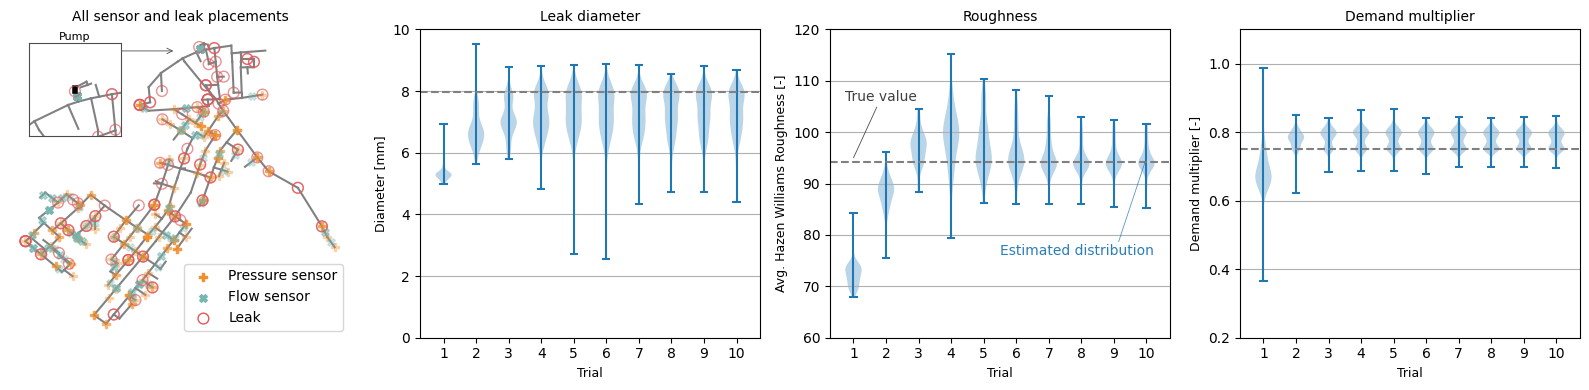

In [12]:
# Plot
fig, axs = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
titles = ['Leak diameter', 'Roughness', 'Demand multiplier']
markers = ['o', 's', '^']


mean_err = np.mean(error_stack, axis=0)

for i in range (0, 3):
    ax = axs.flat[i+1]
    fmt = markers[i] + '-' 
    violins = ax.violinplot(error_stack[:, :, i], rounds)
    #for violin in violins['bodies']:
    #    violin.set_facecolor(SSP_COLORS[i])
    #for partname in ('cbars', 'cmins', 'cmaxes'):
    #    vp = violins[partname]
    #    vp.set_edgecolor(SSP_COLORS[i])
    #ax.plot(rounds, mean_err[:, i], c=[0.12156863, 0.46666667, 0.70588235, 0.75       ])
    ax.set_title(titles[i], fontsize=10)
    ax.set_xlabel("Trial", fontsize=9)
    ax.set_ylabel("Relative Error", fontsize=9)
    ax.grid(axis='y')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.axhline(list(actual_values.values())[i], linestyle='--', c='0.5')

plt.tight_layout(rect=[0, 0, 1, 0.93])
axs.flat[1].set_ylabel('Diameter [mm]')
axs.flat[2].set_ylabel('Avg. Hazen Williams Roughness [-]')
axs.flat[3].set_ylabel('Demand multiplier [-]')
axs.flat[1].set_ylim(0, 10)
axs.flat[2].set_ylim(60, 120)
axs.flat[3].set_ylim(0.2, 1.1)
axs.flat[1].xaxis.set_ticks(rounds)
axs.flat[2].xaxis.set_ticks(rounds)
axs.flat[3].xaxis.set_ticks(rounds)

base_linewidth = 1.5
markersize = 30
pressure_color = '#F28E2B' #'#CCBB44'
flow_color = '#76B7B2' #'#228833'
leak_color = '#E15759' #'#EE6677'

axs.flat[0].axis('off')

for _, r in superlinks.iterrows():
    a, b = int(r.sj_0), int(r.sj_1)
    if a not in pos or b not in pos:
        continue
    (xa, ya), (xb, yb) = pos[a], pos[b]
    color = '0.5'
    axs.flat[0].plot([xa, xb], [ya, yb], color=color, alpha=0.99, linewidth=base_linewidth)

pump_inset = True
inset_pad = 400
if pump_inset and len(PUMPS) > 0:
    p = PUMPS.iloc[0]
    x0, y0 = ID_TO_XY[int(p['sj_0'])]
    x1, y1 = ID_TO_XY[int(p['sj_1'])]
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2

    axin = inset_axes(axs.flat[0], width='30%', height='30%', loc='upper left',
                        borderpad=1)

    for _, r in superlinks.iterrows():
        a, b = int(r.sj_0), int(r.sj_1)
        if a not in pos or b not in pos:
            continue
        (xa, ya), (xb, yb) = pos[a], pos[b]
        color = '0.5'
        axin.plot([xa, xb], [ya, yb], color=color, alpha=0.99, linewidth=base_linewidth)
    #_draw_network(axin, press_ids, flow_ids, leak_ids,
    #                draw_markers=True, edge_lw=0.8, pump_lw=2.5,
    #                star_size=170, label_fontsize=8, label_offset=(4, -7))
    axin.set_xlim(cx - inset_pad, cx + inset_pad)
    axin.set_ylim(cy - inset_pad, cy + inset_pad)
    axin.set_aspect('equal')
    axin.set_xticks([]); axin.set_yticks([])
    for s in axin.spines.values():
        s.set_edgecolor('0.3')
    axin.set_title('Pump', fontsize=8, pad=2)
    arrow_tail_x = 0.305
    arrow_head_x = 0.48
    arrow_y = 0.93
    axs.flat[0].annotate(
        '',
        xy=(arrow_head_x, arrow_y), xycoords='axes fraction',
        xytext=(arrow_tail_x, arrow_y), textcoords='axes fraction',
        arrowprops=dict(arrowstyle='->', color='0.3',
                        lw=0.6, mutation_scale=10,
                        shrinkA=0, shrinkB=0),
        zorder=4,
    )

axs.flat[0].scatter(superjunctions.loc[sampling_results['i_H1'].values, 'map_x'], superjunctions.loc[sampling_results['i_H1'].values, 'map_y'],
            c=pressure_color, s=markersize, marker='P', zorder=2, alpha=0.3)
axs.flat[0].scatter(superjunctions.loc[sampling_results['i_H2'].values, 'map_x'], superjunctions.loc[sampling_results['i_H2'].values, 'map_y'], 
            c=pressure_color, s=markersize, marker='P', zorder=2, alpha=0.3)
axs.flat[0].scatter(superjunctions.loc[sampling_results['i_H2'].values, 'map_x'].iloc[-1], superjunctions.loc[sampling_results['i_H2'].values, 'map_y'].iloc[-1], 
            c=pressure_color, s=markersize, marker='P', zorder=2, alpha=1, label='Pressure sensor')

axs.flat[0].scatter(superlinks.loc[sampling_results['i_Q1'].values, 'map_x'], superlinks.loc[sampling_results['i_Q1'].values, 'map_y'], 
            c=flow_color, s=markersize, marker='X', zorder=2, alpha=0.3)
axs.flat[0].scatter(superlinks.loc[sampling_results['i_Q2'].values, 'map_x'], superlinks.loc[sampling_results['i_Q2'].values, 'map_y'], 
            c=flow_color, s=markersize, marker='X', zorder=2, alpha=0.3)
axs.flat[0].scatter(superlinks.loc[sampling_results['i_Q2'].values, 'map_x'].iloc[-1], superlinks.loc[sampling_results['i_Q2'].values, 'map_y'].iloc[-1], 
            c=flow_color, s=markersize, marker='X', zorder=2, alpha=1, label='Flow sensor')

axs.flat[0].scatter(superjunctions.loc[sampling_results['leak_loc'].values, 'map_x'], superjunctions.loc[sampling_results['leak_loc'].values, 'map_y'], 
            s=2*markersize, edgecolors=leak_color, facecolors='none', zorder=3, alpha=0.65)
axs.flat[0].scatter(superjunctions.loc[sampling_results['leak_loc'].values, 'map_x'].iloc[-1], superjunctions.loc[sampling_results['leak_loc'].values, 'map_y'].iloc[-1], 
            s=2*markersize, edgecolors=leak_color, facecolors='none', zorder=3, alpha=1, label='Leak')

for _, p in PUMPS.iterrows():
    x0, y0 = ID_TO_XY[int(p['sj_0'])]
    x1, y1 = ID_TO_XY[int(p['sj_1'])]
    axin.plot([x0, x1], [y0, y1], color='k', linewidth=4, zorder=3)
axin.scatter(superjunctions.loc[sampling_results['i_H1'].values, 'map_x'], superjunctions.loc[sampling_results['i_H1'].values, 'map_y'],
            c=pressure_color, s=markersize, marker='P', zorder=2, alpha=0.3)
axin.scatter(superjunctions.loc[sampling_results['i_H2'].values, 'map_x'], superjunctions.loc[sampling_results['i_H2'].values, 'map_y'], 
            c=pressure_color, s=markersize, marker='P', zorder=2, alpha=0.3)
axin.scatter(superlinks.loc[sampling_results['i_Q1'].values, 'map_x'], superlinks.loc[sampling_results['i_Q1'].values, 'map_y'], 
            c=flow_color, s=markersize, marker='X', zorder=2, alpha=0.3)
axin.scatter(superlinks.loc[sampling_results['i_Q2'].values, 'map_x'], superlinks.loc[sampling_results['i_Q2'].values, 'map_y'], 
            c=flow_color, s=markersize, marker='X', zorder=2, alpha=0.3)
axin.scatter(superjunctions.loc[sampling_results['leak_loc'].values, 'map_x'], superjunctions.loc[sampling_results['leak_loc'].values, 'map_y'], 
            s=2*markersize, edgecolors=leak_color, facecolors='none', zorder=3, alpha=0.65)


#axs.flat[2].annotate('True value', (0.5, 105), color='0.25')

axs.flat[2].annotate(
    'True value',
    xy=(1, 95), xycoords='data',
    xytext=(0.75, 106), textcoords='data', color='0.25',
    arrowprops=dict(arrowstyle='-', color='0.3',
                    lw=0.6, mutation_scale=10,
                    shrinkA=0, shrinkB=0),
    zorder=4,
)

axs.flat[2].annotate(
    'Estimated distribution',
    xy=(10, 95), xycoords='data',
    xytext=(5.5, 76), textcoords='data', color=[0.12156863, 0.46666667, 0.70588235, 0.95       ],
    arrowprops=dict(arrowstyle='-', color=[0.12156863, 0.46666667, 0.70588235, 0.75       ],
                    lw=0.6, mutation_scale=10,
                    shrinkA=0, shrinkB=0, relpos=(0.75, 0.5)),
    zorder=4,
)

axs.flat[0].legend(fontsize=10, loc=4)
#axs.flat[0].axis('equal')
axs.flat[0].set_title('All sensor and leak placements', fontsize=10)

#plt.axis('equal'); plt.grid(True, alpha=0.2)
#plt.axis('off')
plt.tight_layout()
plt.savefig('all_leak_results.png', dpi=200, bbox_inches='tight')


In [13]:
err_leak_diam = np.abs(error_stack[:, -1, 0].mean() - actual_values['leak'])
pct_err_leak_diam = err_leak_diam / actual_values['leak']
print('Err:', err_leak_diam)
print('Pct. Err:', 100 * pct_err_leak_diam, '%')

Err: 0.734579431407349
Pct. Err: 9.206587863640122 %


In [14]:
err_rough = np.abs(error_stack[:, -1, 1].mean() - actual_values['rough'])
pct_err_rough = err_rough / actual_values['rough']
print('Err:', err_rough)
print('Pct. Err:', 100 * pct_err_rough, '%')

Err: 0.7017030222108218
Pct. Err: 0.7447100262253349 %


In [15]:
err_demand = np.abs(error_stack[:, -1, 2].mean() - actual_values['demand'])
pct_err_demand = err_demand / actual_values['demand']
print('Err:', err_demand)
print('Pct. Err:', 100 * pct_err_demand, '%')

Err: 0.02691665093819584
Pct. Err: 3.5888867917594456 %
